## Library Imports

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

## Data Visualisation

In [5]:
## Read the dataset
df=pd.read_csv('height-weight.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0, 0.5, 'Height')

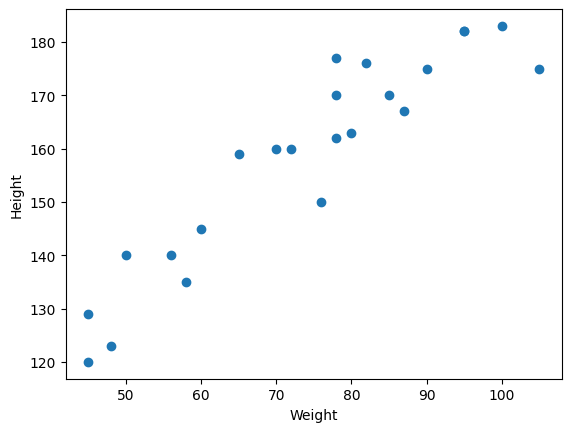

In [6]:
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [7]:
## divide our dataset into independent and dependent edatures
X=df[['Weight']] ##independent feature
y=df['Height'] ##dependent feature

## Train Test split

In [8]:
## Train test split
from sklearn.model_selection import train_test_split

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [10]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((18, 1), (5, 1), (18,), (5,))

## Standardize the dataset

In [1]:
from sklearn.preprocessing import StandardScaler

In [2]:
scaler=StandardScaler()

In [11]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

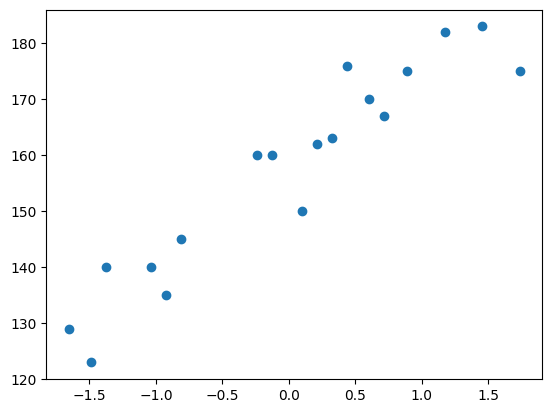

In [12]:
plt.scatter(X_train,y_train)

## Training the Model

In [13]:
from sklearn.linear_model import LinearRegression

In [14]:
regressor=LinearRegression()

In [15]:
regressor.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
print("The slope or coefficient of weight is ",regressor.coef_)
print("Intercept:",regressor.intercept_)

The slope or coefficient of weight is  [17.03440872]
Intercept: 157.5


In [ ]:
X_train_original = scaler.inverse_transform(X_train).ravel()
train_order = np.argsort(X_train_original)
y_train_pred = regressor.predict(X_train)

plt.figure(figsize=(8, 5))
plt.scatter(X_train_original, y_train, label="Training data", alpha=0.7)
plt.plot(
    X_train_original[train_order],
    y_train_pred[train_order],
    color="red",
    linewidth=2,
    label="Regression line",
)
plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("Linear Regression on Training Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Predictions

In [18]:
y_pred_test=regressor.predict(X_test)

In [19]:
y_pred_test,y_test

(array([161.08467086, 161.08467086, 129.3041561 , 177.45645118,
        148.56507414]),
 15    177
 9     170
 0     120
 8     182
 17    159
 Name: Height, dtype: int64)

In [ ]:
X_test_original = scaler.inverse_transform(X_test).ravel()
test_order = np.argsort(X_test_original)
y_test_pred = regressor.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(X_test_original, y_test, label="Test data", color="darkorange", alpha=0.8)
plt.plot(
    X_test_original[test_order],
    y_test_pred[test_order],
    color="red",
    linewidth=2,
    label="Regression line",
)
plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("Linear Regression on Test Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Example prediction

To predict the height for a new person, the input weight must be transformed using the same `StandardScaler` fitted on the training data. The prediction is then made by the trained regression model.

In [29]:
new_weight = np.array([[90]])  # Example weight for prediction
new_weight_scaled = scaler.transform(new_weight)
predicted_height = regressor.predict(new_weight_scaled)[0]

print(f"For a weight of {new_weight[0, 0]:.1f}, the predicted height is {predicted_height:.1f}cm.")

For a weight of 90.0, the predicted height is 172.6cm.


c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## Performance metrics

## What the evaluation metrics tell us

These metrics compare actual heights (`y`) with predicted heights (`y_hat`). Let `n` be the number of observations, `p` the number of input features, and `e_i = y_i - y_hat_i` the residual for observation `i`.

| Metric | Formula | What it tells us |
|---|---|---|
| **Mean Squared Error (MSE)** | `MSE = (1/n) * sum((y_i - y_hat_i)^2)` | Average squared prediction error. Lower is better, but squaring makes it more sensitive to large errors. Its unit is squared height units. |
| **Mean Absolute Error (MAE)** | `MAE = (1/n) * sum(abs(y_i - y_hat_i))` | Average absolute distance between actual and predicted values. Lower is better, and it is easy to interpret because it uses the same units as height. |
| **Root Mean Squared Error (RMSE)** | `RMSE = sqrt(MSE)` | Typical size of a prediction error, with extra sensitivity to large errors. Lower is better and the result is in height units. |
| **R-squared (R^2)** | `R^2 = 1 - [sum((y_i - y_hat_i)^2) / sum((y_i - y_bar)^2)]` | Proportion of variation in height explained by the model. Values closer to 1 indicate a better fit; 0 means no improvement over predicting the mean. |
| **Adjusted R-squared** | `Adjusted R^2 = 1 - (1 - R^2) * (n - 1) / (n - p - 1)` | R-squared adjusted for the number of features and sample size. It is useful when comparing models with different numbers of predictors because unnecessary features are penalized. |

For this single-feature model, `p = 1`. Interpret these metrics on the held-out test set so that performance reflects how the model is likely to perform on unseen data.

### MSE , MAE , RMSE

In [21]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [22]:
mse=mean_squared_error(y_test,y_pred_test)
mae=mean_absolute_error(y_test,y_pred_test)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

109.77592599051664
9.822657814519232
10.477400726827081


### R square

In [23]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred_test)

In [24]:
score

0.776986986042344

### Adjusted R square

In [25]:
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.7026493147231252

## Residual analysis

A **residual** is the difference between an observed value and the model prediction:

`residual = actual value - predicted value`

Residual analysis checks whether the model's errors behave in a reasonable way. For a suitable linear regression model, residuals should be approximately centered around zero, show no obvious pattern, and have a similar spread across the range of predictions.

- A random cloud around zero suggests that a linear relationship is reasonable.
- A curve or systematic pattern suggests that the model may be missing a non-linear relationship.
- A funnel-shaped spread suggests that the error variance changes with the prediction size (heteroscedasticity).
- Individual points far from the rest may be outliers or influential observations.
- A strongly skewed histogram indicates that the errors are not symmetrically distributed.

To perform the analysis, calculate test-set residuals, plot residuals against predicted values, and inspect their distribution. These checks complement numerical metrics: metrics tell us how large the errors are, while residual plots help explain whether the errors show a structural problem.

Mean residual: 6.101
Residual standard deviation: 8.518


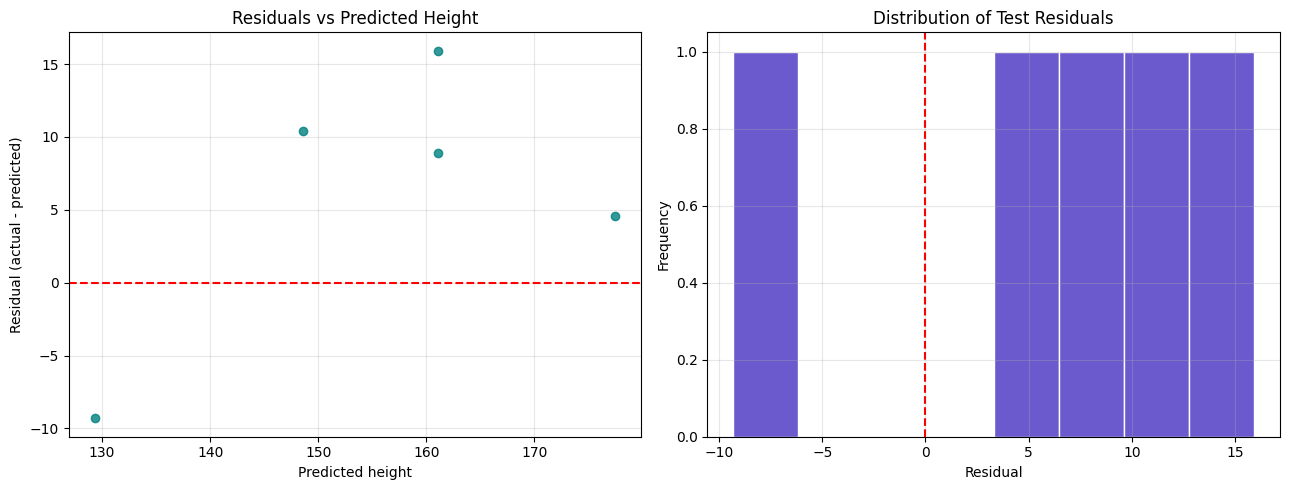

In [26]:
residuals = y_test.to_numpy() - y_pred_test

print(f"Mean residual: {residuals.mean():.3f}")
print(f"Residual standard deviation: {residuals.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_pred_test, residuals, color="teal", alpha=0.8)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Predicted height")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs Predicted Height")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals, bins=8, color="slateblue", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Test Residuals")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion

This project follows a complete linear regression workflow: it loads and visualizes the height-weight data, separates the feature and target, splits the data into training and testing sets, standardizes the input, and trains a linear regression model. The model then predicts heights for unseen weights and is evaluated using error metrics and residual analysis. Together, these steps show both how the model works and how well its predictions generalize to new data.